
Stopped


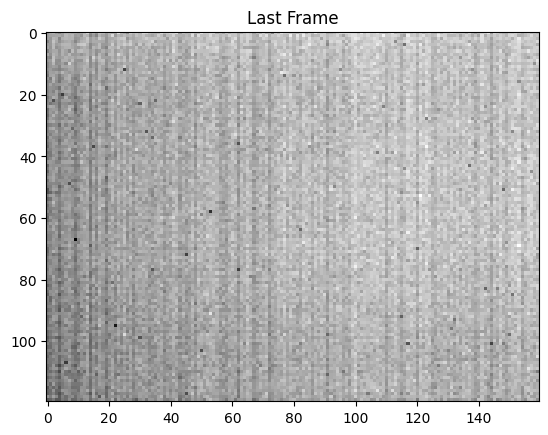

In [1]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

import serial
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output
import os
from datetime import datetime


class ImagePacketDecoder:
    """
    RAW16 UART 图像包解析器（支持行扩展）

    UART 包格式:
        FF FF +
        H * (W + 2) * u16   (Big Endian)

    npy 保存格式:
        shape = (H, W + 2)
        [0:W]   : 图像数据（Gray->Binary）
        [W:W+2] : 行扩展数据（Gray->Binary）
    """

    def __init__(self, width, height, calib_file=None):
        self.width = width
        self.height = height

        # 每行 u16 数（图像 + 行扩展）
        self.line_words = self.width + 2

        # UART payload size
        self.packet_size = 2 + self.height * self.line_words * 2

        self.calib = None
        if calib_file is not None:
            self._load_calibration(calib_file)

    def _load_calibration(self, calib_file):
        calib = np.load(calib_file)

        if calib.shape != (self.height, self.width):
            raise ValueError(
                f"Calibration shape mismatch: "
                f"expected {(self.height, self.width)}, got {calib.shape}"
            )

        self.calib = calib.astype(np.int32)
        print(f"Loaded calibration file: {calib_file}")

    @staticmethod
    def gray_to_binary(img):
        """Gray → Binary（u16，逐位异或）"""
        bin16 = img.copy().astype(np.uint16)
        bin16 ^= bin16 >> 1
        bin16 ^= bin16 >> 2
        bin16 ^= bin16 >> 4
        bin16 ^= bin16 >> 8
        return bin16

    def feed_packet(self, packet):
        if len(packet) != self.packet_size:
            return None
        if packet[0] != 0xFF or packet[1] != 0xFF:
            return None

        data = packet[2:]
        buf8 = np.frombuffer(data, dtype=np.uint8)

        # Big endian u16
        raw16 = (buf8[0::2].astype(np.uint16) << 8) | \
                buf8[1::2].astype(np.uint16)

        raw16_all = raw16.reshape((self.height, self.line_words))

        # 拆分
        raw_img = raw16_all[:, :self.width]
        raw_ext = raw16_all[:, self.width:]

        # 图像 Gray → Binary
        img_bin = self.gray_to_binary(raw_img).astype(np.int32)

        # 冰面校准（只作用于图像区）
        if self.calib is not None:
            img_bin = img_bin - self.calib
            img_bin = np.clip(img_bin, 0, 65535)

        # 行扩展 Gray → Binary
        ext_bin = self.gray_to_binary(raw_ext).astype(np.uint16)

        return (
            img_bin.astype(np.uint16),  # 显示 / 使用
            ext_bin                     # 行扩展
        )


def load_frame_ignore_ext(npy_path, width):
    """
    读取 (H, W+2) npy 文件，忽略行扩展
    """
    frame = np.load(npy_path)

    if frame.ndim != 2:
        raise ValueError("Invalid frame ndim")

    if frame.shape[1] < width:
        raise ValueError("Frame width too small")

    return frame[:, :width]


def run_uart_capture(
    port,
    baud,
    width,
    height,
    calib_file=None,
):
    folder = datetime.now().strftime("capture_%Y%m%d_%H%M%S")
    os.makedirs(folder, exist_ok=True)

    npy_path = os.path.join(folder, "frame.npy")
    print(f"Saving frame to: {npy_path}")

    decoder = ImagePacketDecoder(width, height, calib_file)

    buf = bytearray()
    last_img = None

    try:
        with serial.Serial(port, baud, timeout=0.01) as ser:
            print("Receiving frames... Press Ctrl-C to stop")

            while True:
                chunk = ser.read(4096)
                if not chunk:
                    continue

                buf.extend(chunk)

                while True:
                    idx = buf.find(b'\xFF\xFF')
                    if idx < 0:
                        buf = buf[-1:]
                        break

                    if len(buf) - idx < decoder.packet_size:
                        buf = buf[idx:]
                        break

                    packet = buf[idx:idx + decoder.packet_size]
                    buf = buf[idx + decoder.packet_size:]

                    result = decoder.feed_packet(packet)
                    if result is None:
                        continue

                    img_bin, ext_bin = result

                    # 合并保存 (120, 162)
                    frame_162 = np.concatenate([img_bin, ext_bin], axis=1)
                    np.save(npy_path, frame_162)

                    last_img = img_bin

                    clear_output(wait=True)
                    plt.imshow(img_bin, cmap="gray")
                    plt.title("Binary Image (ignore line ext)")
                    plt.show()

    except KeyboardInterrupt:
        print("\nStopped")

        if last_img is not None:
            plt.figure()
            plt.imshow(last_img, cmap="gray")
            plt.title("Last Frame")
            plt.show()


if __name__ == "__main__":
    run_uart_capture(
        port="COM31",
        baud=5_000_000,
        width=160,
        height=120,
        calib_file=None,
    )


In [ ]:
import numpy as np

# 读取校准文件
calib = np.load("30.2摄氏度原始u16.npy").astype(np.uint16)
height, width = calib.shape

# 转一维
calib_flat = calib.flatten()

with open("calib.h", "w") as f:
    f.write("#ifndef CALIB_H\n#define CALIB_H\n\n")
    f.write(f"#define CALIB_WIDTH {width}\n")
    f.write(f"#define CALIB_HEIGHT {height}\n")
    f.write(f"#define CALIB_SIZE {width*height}\n\n")
    f.write(f"const uint16_t calib[CALIB_SIZE] = {{\n")

    # 每行 16 个元素，方便阅读
    for i in range(0, len(calib_flat), 16):
        row = calib_flat[i:i+16]
        row_str = ", ".join(str(x) for x in row)
        f.write(f"    {row_str},\n")

    f.write("};\n\n#endif // CALIB_H\n")
